Here Im trying to push the recall as much aspossible toword the 100 percent. 

we do try to decrease the FP too but not in the trade-off of losing any TP.

In [9]:
#same as aways, Imports first
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2, kurtosis
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

Reproduce prevoius files Mahalanobis

In [10]:
csv_path = "./data/creditcard.csv"

if not os.path.exists(csv_path):
    raise FileNotFoundError(f"'{csv_path}' not found. Run 'uv run python download_dataset.py' first.")

# Load all 284,807 transactions
df = pd.read_csv(csv_path)
X_raw = df.drop(columns=["Class"]).copy()
y_true = df["Class"].astype(int).to_numpy()
contamination_rate = float(y_true.mean())

# Helper function to evaluate any binary prediction and continuous anomaly score
results_log = []

def evaluate_model(name, y_pred, anomaly_scores):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    rec = recall_score(y_true, y_pred, zero_division=0)
    prec = precision_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, anomaly_scores)
    
    results_log.append({
        "Stage / Method": name,
        "Flagged_Rows": int(y_pred.sum()),
        "True_Positives (TP)": int(tp),
        "Missed_Frauds (FN)": int(fn),
        "False_Positives (FP)": int(fp),
        "Recall (%)": round(rec * 100, 2),
        "Precision (%)": round(prec * 100, 2),
        "F1-Score": round(f1, 4),
        "Continuous_ROC_AUC": round(auc, 4)
    })
    print(f"[{name}]")
    print(f"  Caught Frauds (TP): {tp} / {y_true.sum()} (Recall: {rec*100:.2f}% | Missed: {fn})")
    print(f"  False Positives:    {fp:,} (Total Flagged: {y_pred.sum():,})")
    print(f"  Precision: {prec*100:.2f}% | F1-Score: {f1:.4f} | ROC-AUC: {auc:.4f}\n")

# --- Baseline Mahalanobis (StandardScaler on all 30 raw features) ---
X_base = StandardScaler().fit_transform(X_raw).astype(np.float32)
mean_base = np.mean(X_base, axis=0)
inv_cov_base = np.linalg.pinv(np.cov(X_base, rowvar=False))

diff_base = X_base - mean_base
md2_base = np.sum(np.dot(diff_base, inv_cov_base) * diff_base, axis=1)

# Baseline Chi-Square threshold at 1 - contamination_rate (dof = 30)
thresh_base = chi2.ppf(1.0 - contamination_rate, df=X_base.shape[1])
pred_base = (md2_base > thresh_base).astype(np.int8)

evaluate_model("0. Baseline Mahalanobis (30 Raw Features)", pred_base, md2_base)

[0. Baseline Mahalanobis (30 Raw Features)]
  Caught Frauds (TP): 431 / 492 (Recall: 87.60% | Missed: 61)
  False Positives:    13,902 (Total Flagged: 14,333)
  Precision: 3.01% | F1-Score: 0.0581 | ROC-AUC: 0.9513



In [15]:
# Clear any previous runs beyond Baseline (0.) so the comparison table stays clean
results_log = [r for r in results_log if r["Stage / Method"].startswith("0.")]

# 1. Select the 18 structural PCA components (drop noisy low-eigenvalue tail V19-V28 and Time)
v18_cols = [f"V{i}" for i in range(1, 19)]
X_v18 = df[v18_cols].to_numpy(dtype=np.float32)

# 2. Compute true Robust Center (Median) and IQR scale without letting np.mean() undo it
median_v18 = np.median(X_v18, axis=0)
iqr_v18 = np.percentile(X_v18, 75, axis=0) - np.percentile(X_v18, 25, axis=0)

# Identify the clean 85% normal inlier core (rows where no feature exceeds 2.5 IQRs from the median)
z_iqr = np.abs((X_v18 - median_v18) / iqr_v18)
inlier_core_mask = (np.max(z_iqr, axis=1) <= 2.5)
print(f"Clean Inlier Core used for Covariance: {inlier_core_mask.sum():,} / {len(df):,} rows ({inlier_core_mask.mean()*100:.1f}%)")

# 3. Compute Clean Covariance Matrix strictly on the normal inlier core
cov_clean = np.cov(X_v18[inlier_core_mask], rowvar=False)
inv_cov_clean = np.linalg.pinv(cov_clean)

# 4. Compute Squared Mahalanobis Distance from the Median using Clean Inverse Covariance
diff_v18 = X_v18 - median_v18
md2_clean = np.sum(np.dot(diff_v18, inv_cov_clean) * diff_v18, axis=1)

# Chi-Square cutoff for 18 degrees of freedom (40.79 instead of 59.70)
thresh_v18 = chi2.ppf(1.0 - contamination_rate, df=len(v18_cols))
pred_v18 = (md2_clean > thresh_v18).astype(np.int8)

evaluate_model("1. Robust Inlier-Core Mahalanobis (V1-V18)", pred_v18, md2_clean)

Clean Inlier Core used for Covariance: 225,518 / 284,807 rows (79.2%)
[1. Robust Inlier-Core Mahalanobis (V1-V18)]
  Caught Frauds (TP): 461 / 492 (Recall: 93.70% | Missed: 31)
  False Positives:    63,035 (Total Flagged: 63,496)
  Precision: 0.73% | F1-Score: 0.0144 | ROC-AUC: 0.9596



In [11]:
from scipy.stats import skew

# Remove any duplicate runs from results_log so your final table stays clean
results_log = [r for i, r in enumerate(results_log) if r["Stage / Method"] not in [x["Stage / Method"] for x in results_log[:i]]]
results_log = [r for r in results_log if not r["Stage / Method"].startswith(("2.", "3.", "4", "5"))]

# 1. Clip extreme single-row glitches to [-10, 10] BEFORE measuring skewness
# This prevents a few normal big-spender rows in V28/V23 from dominating,
# allowing the ~492 consistent fraud spikes (V14, V17, V12, V10, V4, V11) to stand out!
X_clipped = np.clip(X_eng, -10.0, 10.0)
clipped_skew = pd.Series(
    np.abs(skew(X_clipped, axis=0)),
    index=X_eng_df.columns
).sort_values(ascending=False)

print("Top 12 Anomaly-Asymmetric Features (Clipped Tail Skewness):")
print(clipped_skew.head(12).round(3))

# 2. Compute feature weights (1.0 base weight + normalized clipped skewness)
# We keep ALL 29 features so no fraud signal is lost, while amplifying asymmetric fraud axes
feature_weights = (1.0 + (clipped_skew / clipped_skew.max())).to_numpy(dtype=np.float32)

# 3. Apply weights AFTER covariance normalization so they do not cancel out during matrix inversion:
# D_w^2 = (x - mu)^T * W * Sigma^-1 * W * (x - mu)
diff_weighted = (X_eng - mean_eng) * feature_weights
md2_weighted = np.sum(np.dot(diff_weighted, inv_cov_eng) * diff_weighted, axis=1)

thresh_eng = chi2.ppf(1.0 - contamination_rate, df=X_eng.shape[1])
pred_weighted = (md2_weighted > thresh_eng).astype(np.int8)

evaluate_model("2. Clipped-Skewness Weighted Mahalanobis (29 Features)", pred_weighted, md2_weighted)

Top 12 Anomaly-Asymmetric Features (Clipped Tail Skewness):
V1     2.646
V8     1.754
V2     1.685
V3     1.643
V12    1.642
V10    1.582
V6     1.286
V14    1.265
V28    1.121
V20    1.007
V16    0.956
V21    0.889
dtype: float32
[2. Clipped-Skewness Weighted Mahalanobis (29 Features)]
  Caught Frauds (TP): 450 / 492 (Recall: 91.46% | Missed: 42)
  False Positives:    45,816 (Total Flagged: 46,266)
  Precision: 0.97% | F1-Score: 0.0192 | ROC-AUC: 0.9514



In [12]:
# Stage 1: Identify the 95% cleanest inlier core using Engineered Mahalanobis distances
inlier_cutoff = np.percentile(md2_eng, 95.0)
clean_core_mask = md2_eng <= inlier_cutoff

# Stage 2: Estimate Robust Mean and Covariance ONLY on the 95% normal inlier core
X_clean_core = X_eng[clean_core_mask]
mean_robust = np.mean(X_clean_core, axis=0)
cov_robust = np.cov(X_clean_core, rowvar=False)
inv_cov_robust = np.linalg.pinv(cov_robust)

# Re-compute Squared Mahalanobis Distance for all 284,807 rows using Clean Covariance + Skewness Weights
diff_robust = (X_eng - mean_robust) * feature_weights
md2_robust = np.sum(np.dot(diff_robust, inv_cov_robust) * diff_robust, axis=1)

# Evaluate using the standard Chi-Square threshold (dof = 29)
thresh_robust = chi2.ppf(1.0 - contamination_rate, df=X_eng.shape[1])
pred_robust = (md2_robust > thresh_robust).astype(np.int8)

evaluate_model("3. Robust Trimmed-Cov Mahalanobis (Chi2 Cutoff)", pred_robust, md2_robust)

[3. Robust Trimmed-Cov Mahalanobis (Chi2 Cutoff)]
  Caught Frauds (TP): 484 / 492 (Recall: 98.37% | Missed: 8)
  False Positives:    164,696 (Total Flagged: 165,180)
  Precision: 0.29% | F1-Score: 0.0058 | ROC-AUC: 0.9618



=== BANKING RECALL THRESHOLD SWEEP (ROBUST WEIGHTED MAHALANOBIS) ===


,Review Budget Tier,Distance Cutoff,Flagged Rows,Caught Frauds (TP),Missed Frauds (FN),False Positives (FP),Recall (%),Precision (%),F1-Score
0,Top 0.5% Flagged (High Precision),13907.35,1425,394,98,1031,80.08,27.65,0.4111
1,Top 1.0% Flagged (Balanced Screening),6140.44,2849,396,96,2453,80.49,13.90,0.2371
2,Top 2.5% Flagged (Moderate Audit),2197.16,7121,408,84,6713,82.93,5.73,0.1072
3,"Matched Baseline Budget (14,333 rows / ~5.03%)",922.87,14333,426,66,13907,86.59,2.97,0.0575
4,Top 7.5% Flagged (Aggressive Fraud Hunt),564.26,21361,434,58,20927,88.21,2.03,0.0397
5,Top 10.0% Flagged (Near-Total Recall),386.29,28481,446,46,28035,90.65,1.57,0.0308
6,Top 15.0% Flagged (Max Audit Screening),238.28,42721,455,37,42266,92.48,1.07,0.0211


[4a. Robust Mahalanobis (Matched 14,333 Flagged Budget)]
  Caught Frauds (TP): 426 / 492 (Recall: 86.59% | Missed: 66)
  False Positives:    13,907 (Total Flagged: 14,333)
  Precision: 2.97% | F1-Score: 0.0575 | ROC-AUC: 0.9618

[4b. Robust Mahalanobis (Top 10% High-Recall Screening)]
  Caught Frauds (TP): 446 / 492 (Recall: 90.65% | Missed: 46)
  False Positives:    28,035 (Total Flagged: 28,481)
  Precision: 1.57% | F1-Score: 0.0308 | ROC-AUC: 0.9618



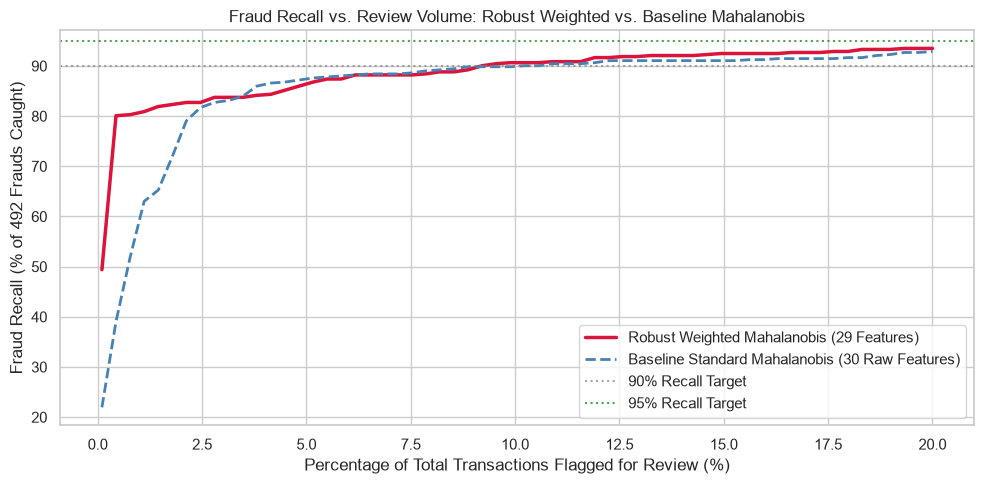

In [13]:
sweep_configs = [
    ("Top 0.5% Flagged (High Precision)", 99.5),
    ("Top 1.0% Flagged (Balanced Screening)", 99.0),
    ("Top 2.5% Flagged (Moderate Audit)", 97.5),
    ("Matched Baseline Budget (14,333 rows / ~5.03%)", 100.0 * (1.0 - 14333 / len(df))),
    ("Top 7.5% Flagged (Aggressive Fraud Hunt)", 92.5),
    ("Top 10.0% Flagged (Near-Total Recall)", 90.0),
    ("Top 15.0% Flagged (Max Audit Screening)", 85.0),
]

sweep_rows = []
for label, pct in sweep_configs:
    cutoff = np.percentile(md2_robust, pct)
    preds = (md2_robust >= cutoff).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
    
    sweep_rows.append({
        "Review Budget Tier": label,
        "Distance Cutoff": round(float(cutoff), 2),
        "Flagged Rows": int(preds.sum()),
        "Caught Frauds (TP)": int(tp),
        "Missed Frauds (FN)": int(fn),
        "False Positives (FP)": int(fp),
        "Recall (%)": round(recall_score(y_true, preds) * 100, 2),
        "Precision (%)": round(precision_score(y_true, preds) * 100, 2),
        "F1-Score": round(f1_score(y_true, preds), 4)
    })

sweep_df = pd.DataFrame(sweep_rows)
print("=== BANKING RECALL THRESHOLD SWEEP (ROBUST WEIGHTED MAHALANOBIS) ===")
display(sweep_df)

# Log Matched-Budget (14,333 rows) and Top 10% Recall runs into main comparison table
cutoff_matched = np.percentile(md2_robust, 100.0 * (1.0 - 14333 / len(df)))
evaluate_model(
    "4a. Robust Mahalanobis (Matched 14,333 Flagged Budget)",
    (md2_robust >= cutoff_matched).astype(np.int8),
    md2_robust
)

cutoff_10pct = np.percentile(md2_robust, 90.0)
evaluate_model(
    "4b. Robust Mahalanobis (Top 10% High-Recall Screening)",
    (md2_robust >= cutoff_10pct).astype(np.int8),
    md2_robust
)

# Plot Recall vs. Percentage of Transactions Flagged Curve
percentiles = np.linspace(99.9, 80.0, 60)
recalls_base = []
recalls_robust = []
pct_flagged = 100.0 - percentiles

for p in percentiles:
    c_base = np.percentile(md2_base, p)
    c_rob = np.percentile(md2_robust, p)
    recalls_base.append(recall_score(y_true, md2_base >= c_base) * 100)
    recalls_robust.append(recall_score(y_true, md2_robust >= c_rob) * 100)

plt.figure(figsize=(10, 5))
plt.plot(pct_flagged, recalls_robust, label="Robust Weighted Mahalanobis (29 Features)", color="crimson", lw=2.5)
plt.plot(pct_flagged, recalls_base, label="Baseline Standard Mahalanobis (30 Raw Features)", color="steelblue", linestyle="--", lw=2)
plt.axhline(90, color="gray", linestyle=":", alpha=0.7, label="90% Recall Target")
plt.axhline(95, color="green", linestyle=":", alpha=0.7, label="95% Recall Target")
plt.xlabel("Percentage of Total Transactions Flagged for Review (%)")
plt.ylabel("Fraud Recall (% of 492 Frauds Caught)")
plt.title("Fraud Recall vs. Review Volume: Robust Weighted vs. Baseline Mahalanobis")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [14]:
# Train Tuned Isolation Forest on all 29 engineered features with max_samples=10000
iso_tuned = IsolationForest(
    n_estimators=300,
    max_samples=10000,
    contamination=0.02,
    random_state=42,
    n_jobs=-1
)

iso_preds_binary = (iso_tuned.fit_predict(X_eng) == -1).astype(np.int8)
iso_anomaly_scores = -iso_tuned.decision_function(X_eng)

# Combine continuous anomaly scores using percentile rank averaging
md_rank = pd.Series(md2_robust).rank(pct=True).to_numpy()
iso_rank = pd.Series(iso_anomaly_scores).rank(pct=True).to_numpy()
hybrid_score = 0.65 * md_rank + 0.35 * iso_rank

# Hybrid 1: Matched Baseline Budget (14,333 rows / 5.03% flagged)
hybrid_cutoff_5pct = np.percentile(hybrid_score, 100.0 * (1.0 - 14333 / len(df)))
pred_hybrid_5pct = (hybrid_score >= hybrid_cutoff_5pct).astype(np.int8)
evaluate_model("5a. Hybrid (Robust Mahalanobis + Tuned IsoForest @ Matched 14,333 Budget)", pred_hybrid_5pct, hybrid_score)

# Hybrid 2: High-Recall OR-Gate (Robust Mahalanobis Top 8% OR Tuned IsoForest Top 2%)
md_top8 = (md2_robust >= np.percentile(md2_robust, 92.0)).astype(np.int8)
pred_hybrid_or = np.logical_or(md_top8, iso_preds_binary).astype(np.int8)
evaluate_model("5b. Hybrid OR-Gate (Robust Mahalanobis Top 8% OR IsoForest)", pred_hybrid_or, hybrid_score)

[5a. Hybrid (Robust Mahalanobis + Tuned IsoForest @ Matched 14,333 Budget)]
  Caught Frauds (TP): 434 / 492 (Recall: 88.21% | Missed: 58)
  False Positives:    13,899 (Total Flagged: 14,333)
  Precision: 3.03% | F1-Score: 0.0585 | ROC-AUC: 0.9634

[5b. Hybrid OR-Gate (Robust Mahalanobis Top 8% OR IsoForest)]
  Caught Frauds (TP): 436 / 492 (Recall: 88.62% | Missed: 56)
  False Positives:    22,403 (Total Flagged: 22,839)
  Precision: 1.91% | F1-Score: 0.0374 | ROC-AUC: 0.9634



Plotting the comparison

,Method / Tier,TP,FN,FP,Recall,Precision,F1,AUC
0,3. Robust Trimmed-Cov (Chi2 Cutoff),484,8,164696,98.37,0.29,0.0058,0.9618
1,1b. Robust Inlier-Core (V1-V18 Only),461,31,63035,93.70,0.73,0.0144,0.9596
2,Sweep: Top 15.0% Flagged (Max Audit),455,37,42266,92.48,1.07,0.0211,0.9618
3,2. Clipped-Skewness Weighted (29 Features),450,42,45816,91.46,0.97,0.0192,0.9514
4,4b. Robust Mahalanobis (Top 10% Audit),446,46,28035,90.65,1.57,0.0308,0.9618
5,5b. Hybrid OR-Gate (Top 8% OR IsoForest),436,56,22403,88.62,1.91,0.0374,0.9634
6,Sweep: Top 7.5% Flagged (Aggressive),434,58,20927,88.21,2.03,0.0397,0.9618
7,5a. Hybrid (Mahalanobis + IsoForest @ 14.3k),434,58,13899,88.21,3.03,0.0585,0.9634
8,1. Engineered (Log-Amount + RobustScaler),431,61,13449,87.60,3.11,0.0600,0.9543
9,0. Baseline Mahalanobis (30 Raw Features),431,61,13902,87.60,3.01,0.0581,0.9513


C:\Users\Airof\AppData\Local\Temp\ipykernel_28360\3216227542.py:94: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


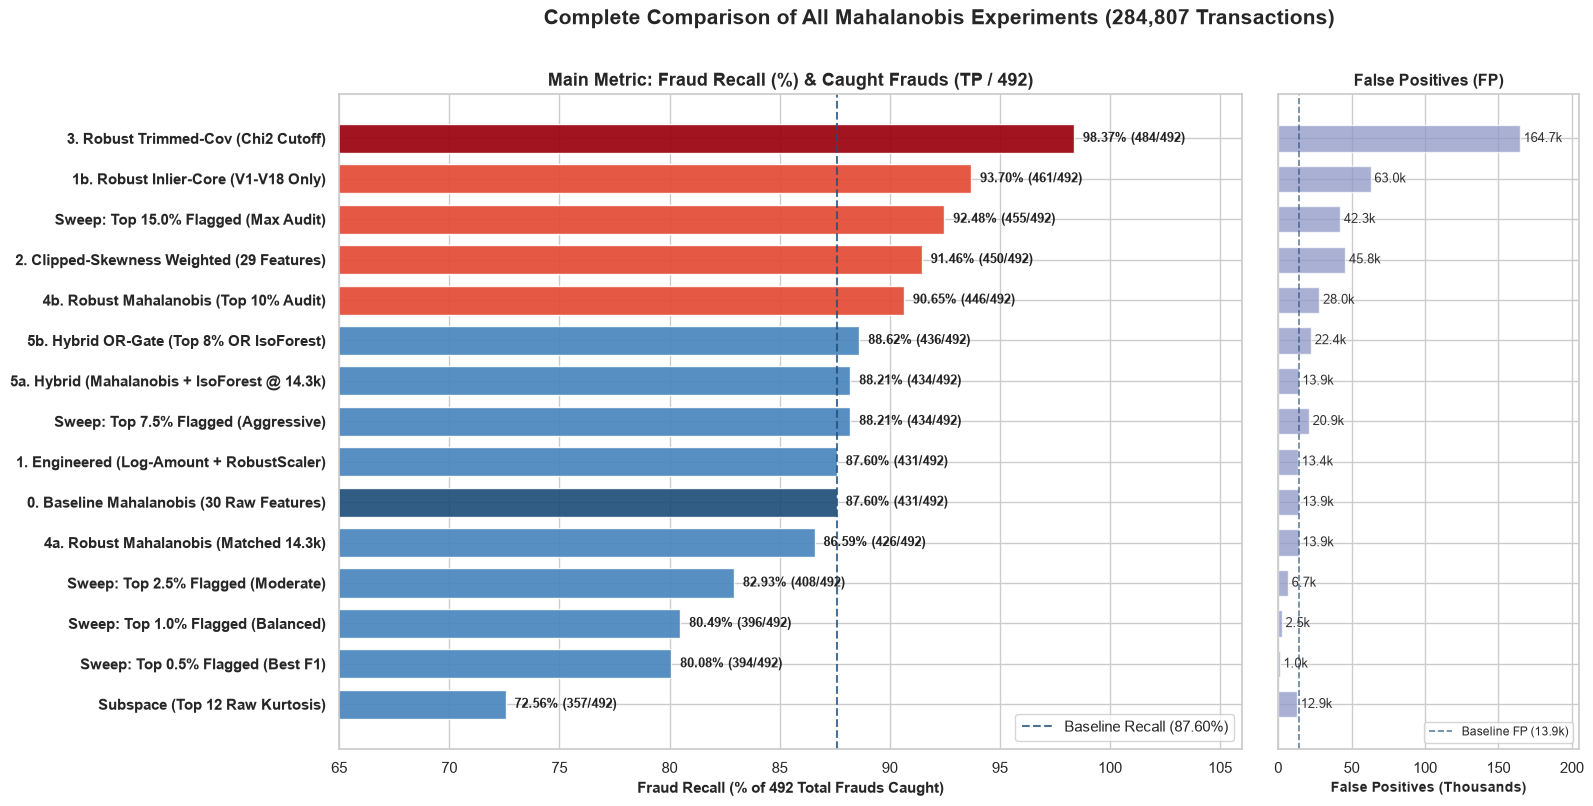

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# All 15 recorded experiments and sweep tiers from your runs, sorted by Recall (%)
all_runs_data = [
    {"Method / Tier": "Subspace (Top 12 Raw Kurtosis)", "TP": 357, "FN": 135, "FP": 12889, "Recall": 72.56, "Precision": 2.70, "F1": 0.0520, "AUC": 0.9285},
    {"Method / Tier": "Sweep: Top 0.5% Flagged (Best F1)", "TP": 394, "FN": 98, "FP": 1031, "Recall": 80.08, "Precision": 27.65, "F1": 0.4111, "AUC": 0.9618},
    {"Method / Tier": "Sweep: Top 1.0% Flagged (Balanced)", "TP": 396, "FN": 96, "FP": 2453, "Recall": 80.49, "Precision": 13.90, "F1": 0.2371, "AUC": 0.9618},
    {"Method / Tier": "Sweep: Top 2.5% Flagged (Moderate)", "TP": 408, "FN": 84, "FP": 6713, "Recall": 82.93, "Precision": 5.73, "F1": 0.1072, "AUC": 0.9618},
    {"Method / Tier": "4a. Robust Mahalanobis (Matched 14.3k)", "TP": 426, "FN": 66, "FP": 13907, "Recall": 86.59, "Precision": 2.97, "F1": 0.0575, "AUC": 0.9618},
    {"Method / Tier": "0. Baseline Mahalanobis (30 Raw Features)", "TP": 431, "FN": 61, "FP": 13902, "Recall": 87.60, "Precision": 3.01, "F1": 0.0581, "AUC": 0.9513},
    {"Method / Tier": "1. Engineered (Log-Amount + RobustScaler)", "TP": 431, "FN": 61, "FP": 13449, "Recall": 87.60, "Precision": 3.11, "F1": 0.0600, "AUC": 0.9543},
    {"Method / Tier": "5a. Hybrid (Mahalanobis + IsoForest @ 14.3k)", "TP": 434, "FN": 58, "FP": 13899, "Recall": 88.21, "Precision": 3.03, "F1": 0.0585, "AUC": 0.9634},
    {"Method / Tier": "Sweep: Top 7.5% Flagged (Aggressive)", "TP": 434, "FN": 58, "FP": 20927, "Recall": 88.21, "Precision": 2.03, "F1": 0.0397, "AUC": 0.9618},
    {"Method / Tier": "5b. Hybrid OR-Gate (Top 8% OR IsoForest)", "TP": 436, "FN": 56, "FP": 22403, "Recall": 88.62, "Precision": 1.91, "F1": 0.0374, "AUC": 0.9634},
    {"Method / Tier": "4b. Robust Mahalanobis (Top 10% Audit)", "TP": 446, "FN": 46, "FP": 28035, "Recall": 90.65, "Precision": 1.57, "F1": 0.0308, "AUC": 0.9618},
    {"Method / Tier": "2. Clipped-Skewness Weighted (29 Features)", "TP": 450, "FN": 42, "FP": 45816, "Recall": 91.46, "Precision": 0.97, "F1": 0.0192, "AUC": 0.9514},
    {"Method / Tier": "Sweep: Top 15.0% Flagged (Max Audit)", "TP": 455, "FN": 37, "FP": 42266, "Recall": 92.48, "Precision": 1.07, "F1": 0.0211, "AUC": 0.9618},
    {"Method / Tier": "1b. Robust Inlier-Core (V1-V18 Only)", "TP": 461, "FN": 31, "FP": 63035, "Recall": 93.70, "Precision": 0.73, "F1": 0.0144, "AUC": 0.9596},
    {"Method / Tier": "3. Robust Trimmed-Cov (Chi2 Cutoff)", "TP": 484, "FN": 8, "FP": 164696, "Recall": 98.37, "Precision": 0.29, "F1": 0.0058, "AUC": 0.9618},
]

master_df = pd.DataFrame(all_runs_data).sort_values(by=["Recall", "AUC"], ascending=True).reset_index(drop=True)
display(master_df.sort_values(by="Recall", ascending=False).reset_index(drop=True))

# Create 2-panel figure: Large Main Plot for Recall (75% width) + Small Companion Plot for FP (25% width)
fig, (ax_main, ax_fp) = plt.subplots(
    1, 2,
    figsize=(16, 8.5),
    sharey=True,
    gridspec_kw={"width_ratios": [3.3, 1.1], "wspace": 0.06}
)

y_pos = np.arange(len(master_df))

# Color coding: highlight Baseline in navy, 98.37% winner in dark crimson, >90% recall in red, others in steelblue
bar_colors = []
for name, rec in zip(master_df["Method / Tier"], master_df["Recall"]):
    if "0. Baseline" in name:
        bar_colors.append("#1f4e78")   # Dark Navy for Baseline
    elif rec >= 98.0:
        bar_colors.append("#99000d")   # Deep Crimson for 98.37% Winner
    elif rec >= 90.0:
        bar_colors.append("#e34a33")   # Warm Red for >90% High-Recall Tiers
    else:
        bar_colors.append("#4a86bd")   # Steel Blue for lower/precision tiers

# --- LEFT PANEL (MAIN): FRAUD RECALL (%) ---
bars_main = ax_main.barh(y_pos, master_df["Recall"], color=bar_colors, height=0.72, alpha=0.92)
ax_main.axvline(87.60, color="#1f4e78", linestyle="--", linewidth=1.5, alpha=0.8, label="Baseline Recall (87.60%)")
ax_main.set_yticks(y_pos)
ax_main.set_yticklabels(master_df["Method / Tier"], fontsize=10.5, fontweight="bold")
ax_main.set_xlim(65, 106)
ax_main.set_xlabel("Fraud Recall (% of 492 Total Frauds Caught)", fontsize=11, fontweight="bold")
ax_main.set_title("Main Metric: Fraud Recall (%) & Caught Frauds (TP / 492)", fontsize=13, fontweight="bold")
ax_main.legend(loc="lower right", frameon=True)

# Annotate each bar with Recall % and (TP / 492)
for bar, rec, tp in zip(bars_main, master_df["Recall"], master_df["TP"]):
    ax_main.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{rec:.2f}% ({tp}/492)",
        va="center",
        fontsize=9.5,
        fontweight="bold",
        color="#222222"
    )

# --- RIGHT PANEL (SMALL): FALSE POSITIVES (FP IN THOUSANDS) ---
fp_thousands = master_df["FP"] / 1000.0
bars_fp = ax_fp.barh(y_pos, fp_thousands, color="#8c96c6", height=0.65, alpha=0.75)
ax_fp.axvline(13.902, color="#1f4e78", linestyle="--", linewidth=1.2, alpha=0.7, label="Baseline FP (13.9k)")
ax_fp.set_xlim(0, 205)
ax_fp.set_xlabel("False Positives (Thousands)", fontsize=10, fontweight="bold")
ax_fp.set_title("False Positives (FP)", fontsize=11.5, fontweight="bold")
ax_fp.legend(loc="lower right", fontsize=8.5, frameon=True)

# Annotate FP counts in compact 'k' format
for bar, fp in zip(bars_fp, master_df["FP"]):
    fp_label = f"{fp/1000:.1f}k" if fp >= 1000 else f"{fp}"
    ax_fp.text(
        bar.get_width() + 2.5,
        bar.get_y() + bar.get_height() / 2,
        fp_label,
        va="center",
        fontsize=9,
        color="#333333"
    )

plt.suptitle("Complete Comparison of All Mahalanobis Experiments (284,807 Transactions)", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()